# Часть 1

In [5]:
with open("movies.txt", "r", encoding="utf-8") as f:
    first = f.readline().strip().split(";")
    five = []

    minimum = 2030
    maximum = 0
    for count, line in enumerate(f, start=1):
            normal_line = line.strip().split(";")
            if not line.strip():
                continue

            normal_line[1] = int(normal_line[1])
            normal_line[3] = float(normal_line[3])
            normal_line[4] = int(normal_line[4])
            normal_line[5] = int(float(normal_line[5]))
            normal_line[6] = float(normal_line[6])
            normal_line[7] = float(normal_line[7])

            if count <= 5:
                five += [normal_line]
            maximum = max(maximum, normal_line[1])
            minimum = min(minimum, normal_line[1])

    print(f"Число строк данных(без заголовка): {count}")
    print("названия столбцов")
    print(" ".join(first) + "\n")
    print("первые 5 записей в читаемом виде")
    for x in five:
        clean = " | ".join(str(item) for item in x)
        print(clean)
    print(
        f"минимальный = {minimum} и максимальный = {maximum} год выпуска среди записей"
    )


Число строк данных(без заголовка): 11272
названия столбцов
title year genre rating votes duration budget gross type

первые 5 записей в читаемом виде
Kate & Leopold | 2001 | Comedy | 6.4 | 77852 | 118 | 48000000.0 | 76019048.0 | movie
I figli del fuoco | 1990 | Horror | 4.8 | 2252 | 97 | 5500000.0 | 50367.0 | movie
Le avventure di Ford Fairlane | 1990 | Action | 6.5 | 16914 | 104 | 20000000.0 | 21413502.0 | movie
Air America | 1990 | Action | 5.8 | 26579 | 113 | 35000000.0 | 33461269.0 | movie
Alice | 1990 | Comedy | 6.6 | 13112 | 106 | 12000000.0 | 7331647.0 | movie
минимальный = 1990 и максимальный = 2020 год выпуска среди записей


# Часть 2


## 1 Гистограмма распределения рейтингов.

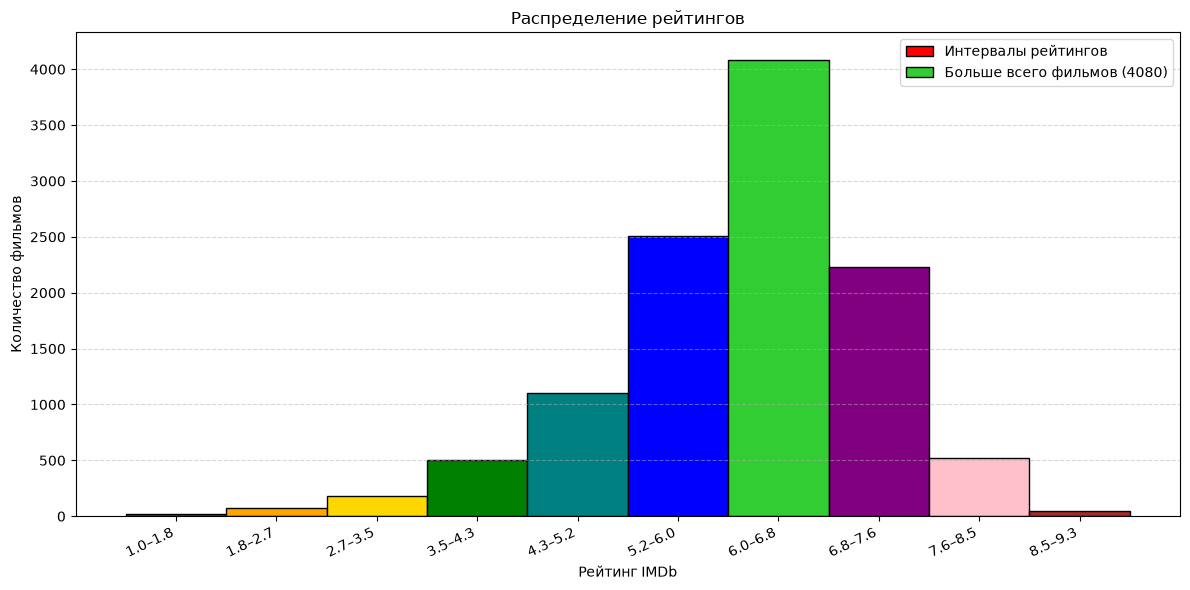

In [2]:
import matplotlib.pyplot as plt
import numpy as np

with open("movies.txt", "r", encoding="utf-8") as f:
    first = f.readline().strip().split(";")
    all_nrmalized = []

    for line in f:
        normal_line = line.strip().split(";")
        all_nrmalized += [normal_line]

raiting = []

for x in all_nrmalized:
    raiting.append(float(x[3]))

fig, ax = plt.subplots(figsize=(12, 6))

n, bins, patches = ax.hist(
    raiting,
    bins=10,
    edgecolor="black",
    label="Интервалы рейтингов",
)


colors = [
    "red",
    "orange",
    "gold",
    "green",
    "teal",
    "blue",
    "indigo",
    "purple",
    "pink",
    "brown",
]

for i in range(len(patches)):
    patches[i].set_facecolor(colors[i % len(colors)])

max_i = list(n).index(max(n))
patches[max_i].set_facecolor("limegreen")
patches[max_i].set_label(f"Больше всего фильмов ({int(n[max_i])})")

centers = []
labels = []
for i in range(len(bins) - 1):
    center = (bins[i] + bins[i + 1]) / 2
    centers.append(center)
    labels.append(f"{round(bins[i],1)}–{round(bins[i + 1],1)}")

ax.set_xticks(centers)
ax.set_xticklabels(labels, rotation=25, ha="right")

ax.set_title("Распределение рейтингов")
ax.set_xlabel("Рейтинг IMDb")
ax.set_ylabel("Количество фильмов")

ax.set_ylim(0, max(n) + 250)
ax.grid(True, axis="y", linestyle="--", alpha=0.5)
ax.legend()

fig.tight_layout()
fig.savefig("movies_raitings.png", dpi=150)
plt.show()

## 2 Столбчатая диаграмма топ-10 жанров по количеству фильмов.

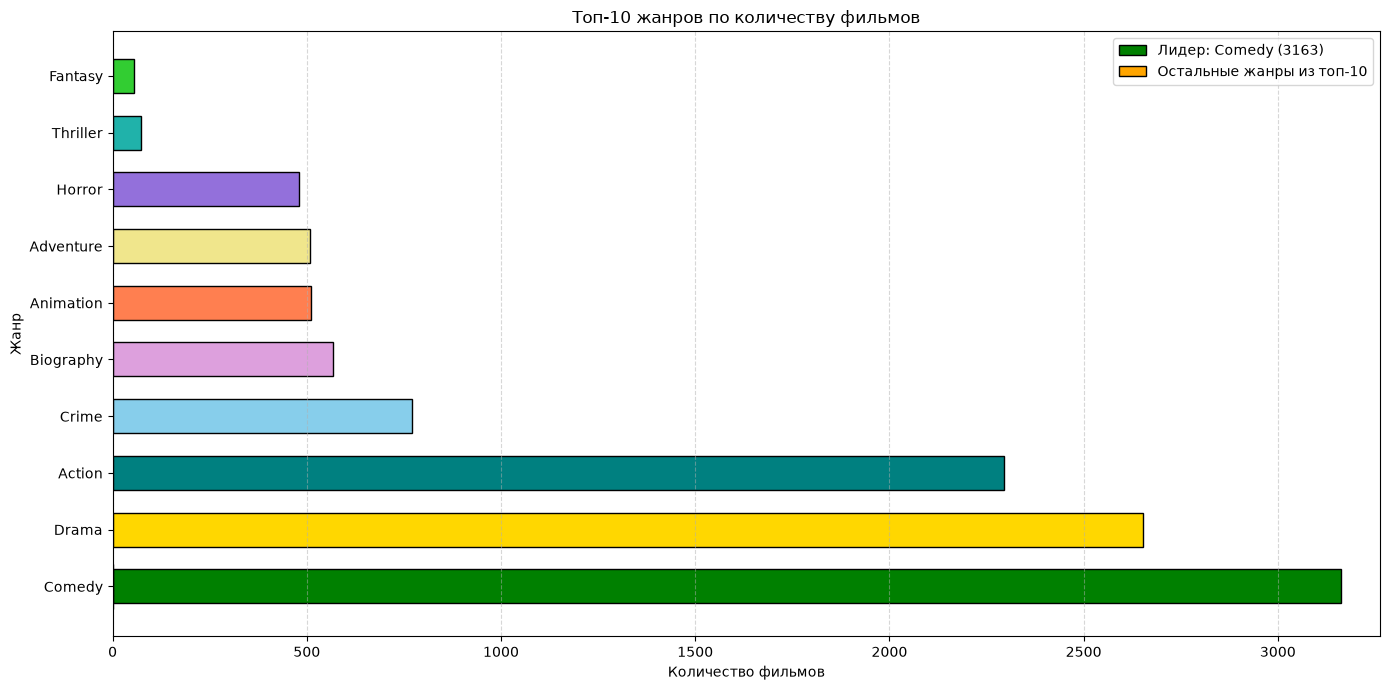

In [3]:
import matplotlib.pyplot as plt

with open("movies.txt", "r", encoding="utf-8") as f:
    first = f.readline().strip().split(";")
    all_nrmalized = []

    for line in f:
        normal_line = line.strip().split(";")
        all_nrmalized += [normal_line]

geners = []

for x in all_nrmalized:
    geners.append(x[2])

geners = list(set(geners))
movies_geners = []

for x in geners:
    count = 0
    for line in all_nrmalized:
        if line[2] == x:
            count += 1
    movies_geners += [count]

pairs = []

for i in range(len(geners)):
    pairs += [[movies_geners[i], geners[i]]]

pairs.sort(reverse=True)

top_geners = [pairs[x][1] for x in range(10)]
top_counts = [pairs[x][0] for x in range(10)]


y = np.arange(len(top_geners))
max_idx = int(np.argmax(top_counts))

fig, ax = plt.subplots(figsize=(14, 7))

colors = [
    "orange",
    "gold",
    "teal",
    "skyblue",
    "plum",
    "coral",
    "khaki",
    "mediumpurple",
    "lightseagreen",
    "limegreen",
]

bars = ax.barh(y, top_counts, height=0.6, color=colors[: len(top_geners)], edgecolor="black")

bars[max_idx].set_color("green")
bars[max_idx].set_edgecolor("black")
bars[max_idx].set_label(f"Лидер: {top_geners[max_idx]} ({top_counts[max_idx]})")

ax.barh([0], [0], color="orange", edgecolor="black", label="Остальные жанры из топ-10")

ax.set_title("Топ-10 жанров по количеству фильмов")
ax.set_xlabel("Количество фильмов")
ax.set_ylabel("Жанр")

ax.set_yticks(y)
ax.set_yticklabels(top_geners)

ax.set_xlim(0, max(top_counts) + 100)
ax.grid(True, axis="x", linestyle="--", alpha=0.5)
ax.legend(loc="upper right")

fig.tight_layout()
fig.savefig("genere.png", dpi=150)
plt.show()

## 3 Круговая диаграмма распределения фильмов по жанрам (топ-5 жанров + категория «Другие»)

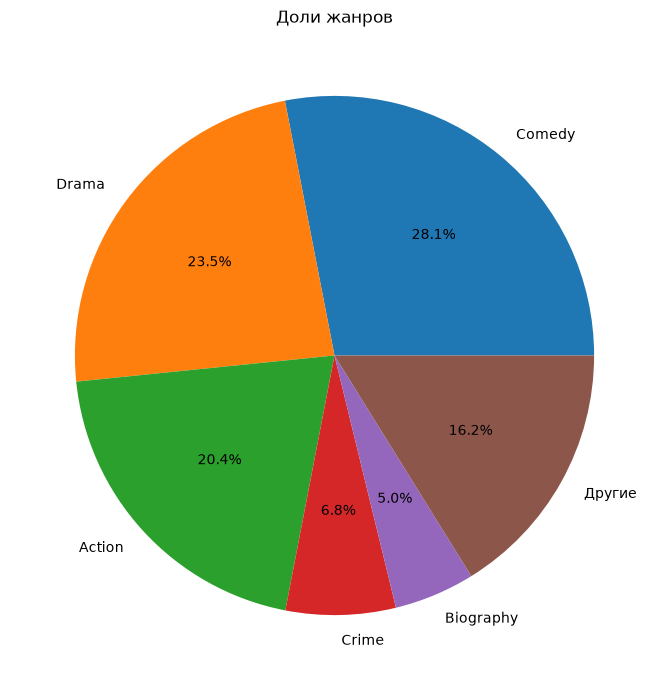

In [4]:
import matplotlib.pyplot as plt
import numpy as np

with open("movies.txt", "r", encoding="utf-8") as f:
    first = f.readline().strip().split(";")
    all_nrmalized = []

    for line in f:
        normal_line = line.strip().split(";")
        all_nrmalized += [normal_line]

geners = []

for x in all_nrmalized:
    geners.append(x[2])

geners = list(set(geners))
movies_geners = []

for x in geners:
    count = 0
    for line in all_nrmalized:
        if line[2] == x:
            count += 1
    movies_geners += [count]

pairs = []

for i in range(len(geners)):
    pairs += [[movies_geners[i], geners[i]]]

pairs.sort(reverse=True)

top_geners = [pairs[x][1] for x in range(5)] + ["Другие"]
top_counts = [pairs[x][0] for x in range(5)]
other_counts = sum([pairs[x][0] for x in range(len(pairs))]) - sum(
    [x for x in top_counts]
)
top_counts.append(other_counts)


fig, ax = plt.subplots(figsize=(7, 7))

ax.pie(top_counts, labels=top_geners, autopct="%1.1f%%")

ax.set_title("Доли жанров")


fig.tight_layout()
fig.savefig("generes_pie.png", dpi=150)
plt.show()

# Часть 3

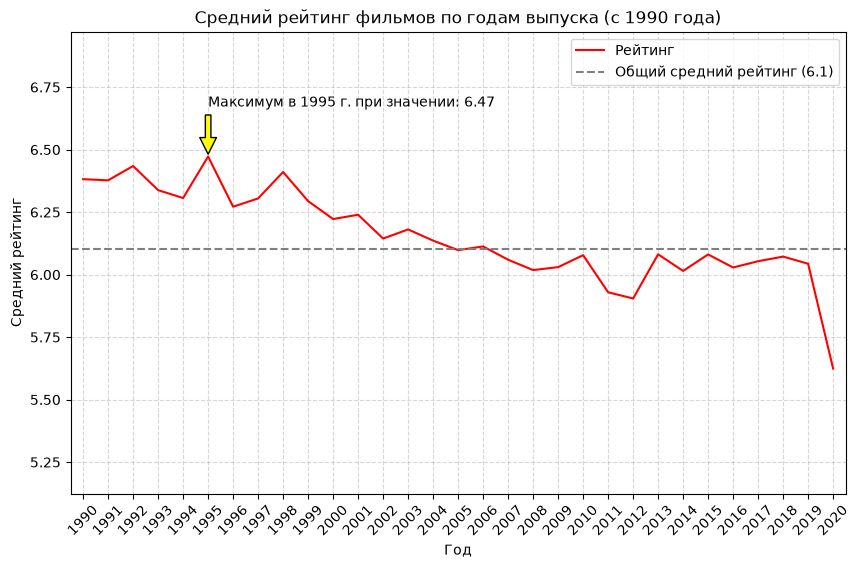

Максимальный средний рейтинг: 6.47 в 1995 году
Общий средний рейтинг: 6.1
Пик ВЫШЕ общего среднего рейтинга.


In [23]:
import matplotlib.pyplot as plt
import numpy as np

with open("movies.txt", "r", encoding="utf-8") as f:
    first = f.readline().strip().split(";")
    all_nrmalized = []

    for line in f:
        normal_line = line.strip().split(";")
        all_nrmalized += [normal_line]

years = []

for i in all_nrmalized:
    years.append(i[1])

year_dict = {y: [] for y in sorted(set(years))}
x_graph = sorted(set(years))

for i in all_nrmalized:
    year = i[1]
    raiting = i[3]

    year_dict[year].append(raiting)

y_graph = []
for i in year_dict.items():
    suma = 0
    for x in i[1]:
        suma += float(x)
    y_graph.append(suma / len(i[1]))

sr_overal = 0
for i in all_nrmalized:
    sr_overal += float(i[3])
sr_overal /= len(all_nrmalized)


fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(x_graph, y_graph, linestyle="-", color="red", label="Рейтинг")
max_idx = int(np.argmax(y_graph))
plt.annotate(
    f"Максимум в {x_graph[max_idx]} г. при значении: {round(max(y_graph), 2)}",
    xy=(x_graph[max_idx], max(y_graph)),
    xytext=(x_graph[max_idx], max(y_graph) + 0.2),
    arrowprops={"facecolor": "yellow", "shrink": 0.05},
)

ax.axhline(
    sr_overal,
    color="grey",
    linestyle="--",
    label=f"Общий средний рейтинг ({round(sr_overal, 2)})",
)
ax.set_title("Средний рейтинг фильмов по годам выпуска (с 1990 года)")
ax.set_xlabel("Год")
ax.set_ylabel("Средний рейтинг")
ax.set_xlim(-0.5, len(x_graph) - 0.5)
ax.set_ylim(min(y_graph) - 0.5, max(y_graph) + 0.5)
ax.set_xticks(x_graph)
ax.set_xticklabels(x_graph, rotation=45)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper right")

fig.savefig("sr_raiting.png", dpi=150)
plt.show()


print(
    f"Максимальный средний рейтинг: {round(max(y_graph), 2)} в {x_graph[max_idx]} году"
)
print(f"Общий средний рейтинг: {round(sr_overal, 2)}")
if max(y_graph) > sr_overal:
    print("Пик ВЫШЕ общего среднего рейтинга.")
else:
    print("Пик НИЖЕ общего среднего рейтинга.")